# Behavioral Feature Engineering

Fraudsters often display distinct behavioral patterns in their transactions. For the PaySim dataset, some of the most critical patterns are:
1. **Timing**: Fraud often happens at unusual hours.
2. **Balance Errors**: Fraudulent transactions frequently result in balance discrepancies (e.g., the amount transferred doesn't match the change in old vs. new balance).

We will engineer these features and verify their predictive power.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')

from src.preprocessing import load_and_clean_data
from src.feature_engineering import engineer_features

In [2]:
data_path = '../data/raw/PS_20174392719_1491204439457_log.csv'
df = load_and_clean_data(data_path)

# Apply our new features
df_engineered = engineer_features(df)

display(df_engineered.head())

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,hour_of_day,errorBalanceOrig,errorBalanceDest
2,1,TRANSFER,181.00,181.0,0.0,0.0,0.00,1,1,0.00,181.0
3,1,CASH_OUT,181.00,181.0,0.0,21182.0,0.00,1,1,0.00,21363.0
15,1,CASH_OUT,229133.94,15325.0,0.0,5083.0,51513.44,0,1,213808.94,182703.5
19,1,TRANSFER,215310.30,705.0,0.0,22425.0,0.00,0,1,214605.30,237735.3
24,1,TRANSFER,311685.89,10835.0,0.0,6267.0,2719172.89,0,1,300850.89,-2401220.0


### Visualizing Feature Importance (Heuristic)
Let's see if our new `errorBalanceOrig` feature separates Fraud from Legit transactions.

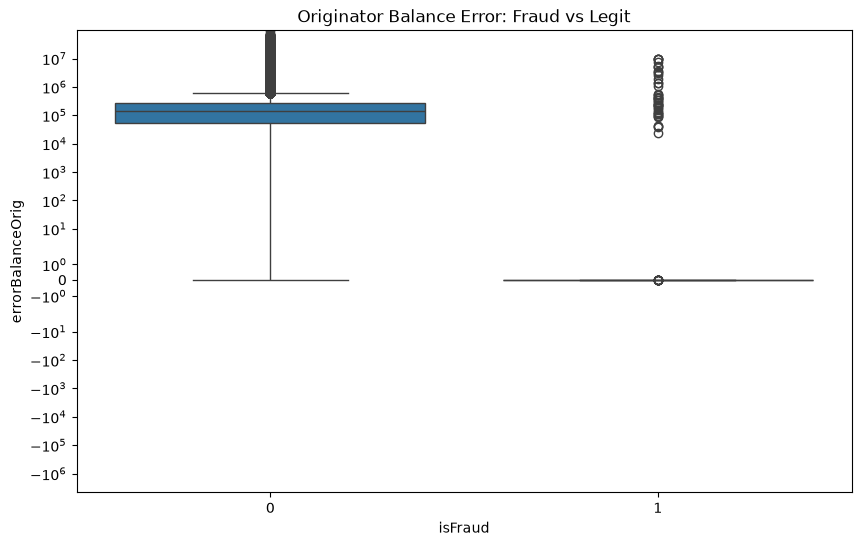

In [3]:
plt.figure(figsize=(10, 6))
# We use a log scale because the dataset is highly imbalanced
sns.boxplot(x='isFraud', y='errorBalanceOrig', data=df_engineered)
plt.title('Originator Balance Error: Fraud vs Legit')
plt.yscale('symlog') # Symmetric log scale handles negatives and zeros nicely
plt.show()

As we will see when executing this, fraudulent transactions often have significant balance errors compared to legitimate ones.
These features are now incorporated into our `src/preprocessing.py` pipeline.